Universes for the purpose of expressing repeated structures.

(Without auxiliary coordinate systems in OpenMC which are present in MCNP, this one is somewhat annoying!)

Also, roulette and particle-splitting don't happen unless weight windows are present, which requires some additional steps to create and are not enabled by default. Hence, there is no analogue of MCNP's neutron importance construct (imp:n=1) here.

Source definitions present:
SDEF erg=d1 cel=d2 rad=d5 ext=d6 axs=0 0 1 pos=d7


Tally definitions present:
f4:n 2 3 4 5 6 12 13 14 15 (specifies neutron flux tallies in the listed cells, according to track length estimate f4)
e4 1 3 5 7 9 11 13 (specifies energy tally)


In [4]:
import openmc 
import numpy as np

materials=openmc.Materials()
materials.cross_sections='/home/jovibuca/endf/endfb-viii.0-hdf5/cross_sections.xml'

carbon = openmc.Material()
carbon.add_nuclide('C12',1)
carbon.set_density('g/cc',0.5)
materials.append(carbon)

uranium=openmc.Material()
uranium.add_nuclide('U235',1)
uranium.set_density('g/cc',19)
materials.append(uranium)

# Surface definitions
s1 = openmc.XPlane(-2)
s2 = openmc.YPlane(2)
s3 = openmc.XPlane(2)
s4=openmc.YPlane(-2)
s5=openmc.ZPlane(-2)
s6=openmc.ZPlane(2)
s7=openmc.Sphere(r=15, boundary_type='vacuum')
s8=openmc.XPlane(-0.7)
s9=openmc.YPlane(0.7)
s10=openmc.XPlane(0.7)
s11=openmc.YPlane(-0.7)
s12=openmc.ZCylinder(r=0.1)

# Universe 2 definition (Four disks arranged as the corners of a square, to go inside the little boxes)
u2_base = -s12
c12_region = u2_base.translate((-0.3, .3, 0))
c12 = openmc.Cell(fill=uranium, region=c12_region)

c13_region = u2_base.translate((0.3,0.3,0))
c13 = openmc.Cell(fill=uranium, region=c13_region)

c14_region=u2_base.translate((0.3,-0.3,0))
c14 = openmc.Cell(fill=uranium, region=c14_region)

c15_region=u2_base.translate((-0.3,-0.3,0))
c15 = openmc.Cell(fill=uranium, region=c15_region)

c16 = openmc.Cell(fill=carbon, region=~c12.region & ~c13.region & ~c14.region & ~c15.region)

u2 = openmc.Universe(cells=[c12,c13,c14,c15,c16])

c7 = openmc.Cell(fill=None,region=+s7)

# Universe 1 definition (Little boxes)
u1_base=+s8&-s9 & -s10 & +s11
c8_region=u1_base.translate((-0.9,0.9,0))
c8 = openmc.Cell(fill=u2,region=c8_region)
c8.translation=(-0.9,0.9,0)

c9_region=u1_base.translate((0.9,0.9,0))
c9 = openmc.Cell(fill=u2,region=c9_region)
c9.translation=(0.9,0.9,0)

c10_region=u1_base.translate((0.1,-0.9,0))
c10 = openmc.Cell(fill=u2,region=c10_region)
c10.translation=(0.1,-0.9,0)

c11 =openmc.Cell(fill=uranium, region=~c8.region & ~c9.region & ~c10.region)
u1 = openmc.Universe(cells=[c8,c9,c10,c11])

# Fill in big boxes
tr2 = (-6,7,1.2)
tr3 = (7, 6, 1.1)
tr4 = (8, -5, 1.4)
tr5  = (-1,-4,1)
tr5_rotate = (0,0,-40)
tr6 = (-9,-2,1.3)

base = +s1&-s2&-s3&+s4&+s5&-s6

c2_region = base.translate(tr2)
c2 = openmc.Cell(fill=u1, region=c2_region)
c2.translation = tr2

c3_region = base.translate(tr3)
c3 = openmc.Cell(fill=u1, region=c3_region)
c3.translation = tr3

c4_region = base.translate(tr4)
c4 = openmc.Cell(fill=u1, region=c4_region)
c4.translation = tr4

c5_region= base.rotate(tr5_rotate)
c5_region=c5_region.translate(tr5)
c5=openmc.Cell(fill=u1,region=c5_region)
c5.rotation=tr5_rotate
c5.translation=tr5

c6_region=base.translate(tr6)
c6=openmc.Cell(fill=u1,region=c6_region)
c6.translation=tr6

c1 = openmc.Cell(fill=carbon,region=-s7&~c2.region&~c3.region&~c4.region&~c5.region&~c6.region) 

geometry=openmc.Geometry([c1,c2,c3,c4,c5,c6,c7,c8,c9,c10,c11,c12,c13,c14,c15,c16])



model = openmc.model.Model()
model.geometry=geometry
model.materials=materials

settings=openmc.Settings()
model.settings=settings

In [5]:
w = 25
plots = openmc.Plots()

level = 1
plot = openmc.SlicePlot()
plot.basis = 'xy'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
#plot.level=level
plots.append(plot)

plot = openmc.SlicePlot()
plot.basis = 'xz'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
#plot.level=level
plots.append(plot)

plot = openmc.SlicePlot()
plot.basis = 'yz'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
#plot.level = level
plots.append(plot)

model.plots=plots
model.export_to_xml()

Here's the output from openmc-plotter:

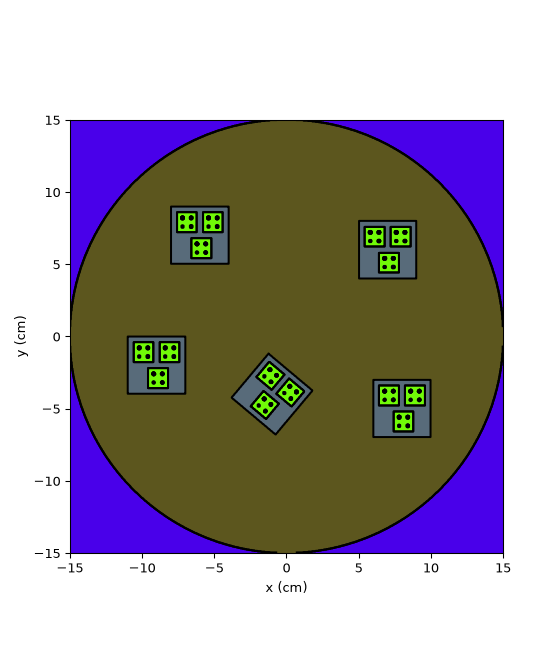

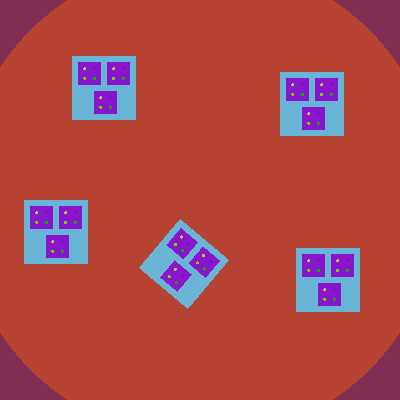

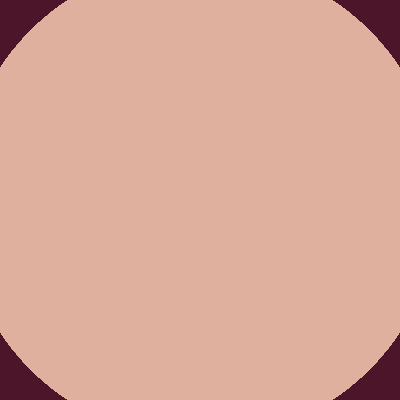

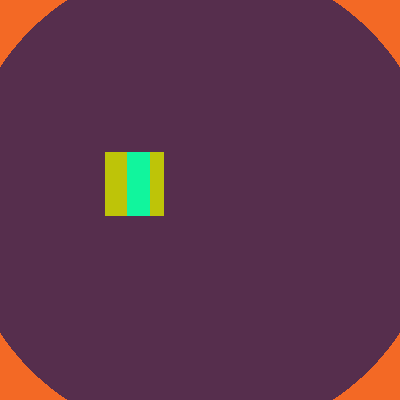

In [3]:
openmc.plot_inline(plots)